# 12b · Live RAG and separate quality signals

## The engineering question
Does the generator use the right evidence, cite it, and decline questions the corpus cannot answer?

**Learning outcomes:** run real local generation; distinguish retrieval coverage, required-fact checks, citation validity, and support; inspect no-answer and conflicting-source cases; retain full fictional-data traces; budget prompt and output tokens.

This lesson uses the pinned Qwen 1.5B model natively on Metal with bfloat16, selected by the measured pilot. Retrieval uses CPU models and Docker Qdrant. We prepare all contexts, release retrieval models, then load the generator to limit the working set. Calls are greedy, capped at 96 new tokens with a cooperative 45-second generation limit. Kernel execution also has a deadline; a serving request timeout alone would not cancel native model computation.

Automated fact checks are deliberately narrow regexes derived from the approved source facts. A gold-span citation is a support proxy; it is not a general entailment judge. Read every saved answer for extra claims, negation errors, and attribution. Generation failures remain results rather than being replaced by canned answers.

**Observed evaluation failure in the reference run:** d02 said a reset would preserve settings and then quoted that it erases them. Both the required-keyword check and gold-span citation proxy passed. d06 included all three menu words but placed them in the wrong order. These are concrete false positives of the automated checks. The author claim review is recorded in `docs/RAG_RESULTS.md`; the small model is not qualified to provide unattended product support.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from vector_masterclass.lesson import LessonRun
from vector_masterclass.config import root

plt.rcParams.update(
    {"figure.figsize": (8, 4), "axes.spines.top": False, "axes.spines.right": False}
)
lesson = LessonRun("12b", "G", docker=True)
print("Kernel:", sys.executable)
print("Workspace:", root())

Kernel: /Users/markcastillo/git/vector-masterclass/.venv/bin/python3
Workspace: /Users/markcastillo/git/vector-masterclass


,query,condition,retrieval_coverage,required_fact_pattern_pass,citations_resolve,cited_gold_span,exact_abstention,answer
0,d01,retrieved,1.0,True,True,True,False,The Atlas router's warranty covers it for two ...
1,d02,retrieved,1.0,True,True,True,False,"Yes, an Atlas factory reset will preserve your..."
2,d03,retrieved,1.0,True,True,True,False,Based on the provided evidence:\n\n- E104 in A...
3,d04,retrieved,1.0,True,True,True,False,"According to Evidence [E1], updating Atlas fir..."
4,d05,retrieved,1.0,False,False,False,True,Insufficient evidence.
5,d06,retrieved,1.0,True,False,False,False,"Based on the provided evidence, you can downlo..."
6,t01,retrieved,1.0,True,False,False,False,"Based on the provided evidence (E1), a Boreal ..."
7,t02,retrieved,1.0,True,False,False,False,"According to Evidence E1, you should hold the ..."
8,t03,retrieved,1.0,False,True,True,False,Based on the provided evidence:\n\n- **[E1]** ...
9,t04,retrieved,1.0,False,False,False,True,Insufficient evidence.


Full response for review: d02 Will an Atlas factory reset preserve my network configuration?
Yes, an Atlas factory reset will preserve your network configuration. This can be inferred from Evidence [E1], which states that "A factory reset erases saved network settings." Therefore, if you perform a factory reset on an Atlas router, it will remove all saved network configurations, ensuring they are preserved during this process.

Full response for review: d06 Where do I download an Atlas configuration backup?
Based on the provided evidence, you can download an Atlas configuration backup by exporting it from the device's settings. Specifically, follow these steps:

1. Go to the "Settings" menu.
2. Select "Export".
3. Choose "Backup".
4. Then, choose "Export".

The exported file will include Wi-Fi credentials if you have configured them. This process allows you to back up your configuration securely and store it in an accessible location.

Full response for review: t03 Our Boreal shows E10

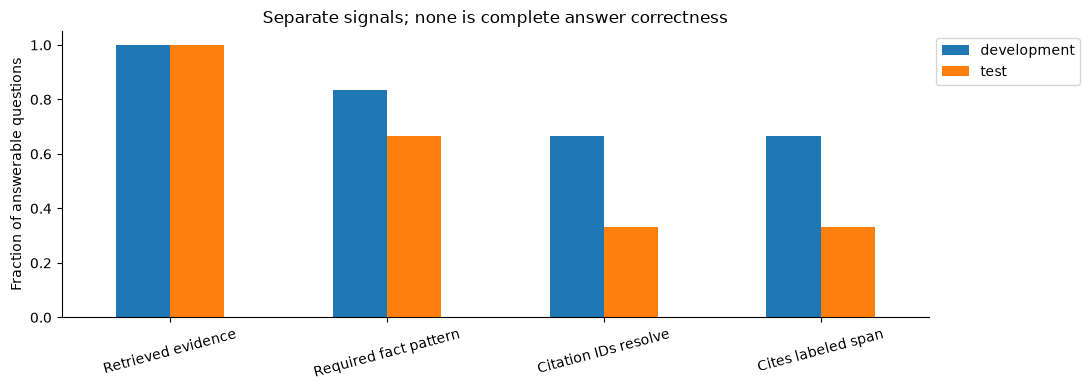

In [3]:
from uuid import uuid4
from transformers import AutoTokenizer
from vector_masterclass.config import model_path
from vector_masterclass.data import documents, queries, validate_gold
from vector_masterclass.chunking import chunk_document
from vector_masterclass.store import VectorIndex
from vector_masterclass.context import assemble
from vector_masterclass.metrics import evidence_coverage
from vector_masterclass.models import release_models
from vector_masterclass.rag import answer, score_answer
from vector_masterclass.evidence import json_write
from vector_masterclass.schema import Document

assert validate_gold()["human_review"] == "approved"
docs = documents(tenant="public")
tokenizer = AutoTokenizer.from_pretrained(str(model_path("generator")), local_files_only=True)
index = VectorIndex("vmc_12b_" + uuid4().hex[:8])
index.create()
prepared = []
try:
    for doc in docs:
        index.upsert(chunk_document(doc), document_id=doc.id)
    for q in queries():
        hits = index.search(q.text, tenant=q.tenant, mode="hybrid", k=5, exact=True)
        context = assemble([h.chunk for h in hits], docs, tokenizer, 384, tenant=q.tenant)
        prepared.append((q, context))
finally:
    index.drop()
    index.close()
release_models()
rows, traces = [], []
for q, context in prepared:
    result = answer(q.text, context)
    traces.append(result | {"query_id": q.id, "condition": "retrieved"})
    rows.append(
        score_answer(q, result)
        | {
            "condition": "retrieved",
            "retrieval_coverage": evidence_coverage(context["chunks"], q.evidence)["coverage"],
        }
    )
# Controlled retrieval ablation: the real generator sees no evidence.
q = queries("development")[0]
empty = assemble([], docs, tokenizer, 384, tenant=q.tenant)
result = answer(q.text, empty)
traces.append(result | {"query_id": q.id, "condition": "empty-context ablation"})
rows.append(
    score_answer(q, result) | {"condition": "empty-context ablation", "retrieval_coverage": 0.0}
)
# Explicitly synthetic conflicting-source fixture, separate from approved gold.
original = next(d for d in docs if d.id == "atlas-warranty")
conflicting = Document(
    id="conflicting-warranty-fixture",
    revision="1",
    title="Synthetic conflict",
    text="Atlas router warranty lasts three years from the purchase date.",
)
conflict_sources = [original, conflicting]
conflict_context = assemble(
    [chunk_document(d, "document")[0] for d in conflict_sources],
    conflict_sources,
    tokenizer,
    256,
    tenant="public",
)
conflict = answer(
    "How long is the Atlas warranty? Identify any conflict in the supplied sources.",
    conflict_context,
)
traces.append(conflict | {"query_id": "synthetic-conflict", "condition": "conflicting sources"})
json_write(lesson.path / "generation-traces.json", traces)
results = lesson.table(pd.DataFrame(rows))
display(
    results[
        [
            "query",
            "condition",
            "retrieval_coverage",
            "required_fact_pattern_pass",
            "citations_resolve",
            "cited_gold_span",
            "exact_abstention",
            "answer",
        ]
    ]
)
for id_ in ["d02", "d06", "t03", "d07"]:
    record = next(t for t in traces if t["query_id"] == id_)
    print("Full response for review:", id_, record["question"])
    print(record["text"])
    print()
print("Conflict response:", conflict["text"])
summary = (
    results[results.condition.eq("retrieved") & results.answerable]
    .groupby("split")[
        ["retrieval_coverage", "required_fact_pattern_pass", "citations_resolve", "cited_gold_span"]
    ]
    .mean()
)
fig, ax = plt.subplots(figsize=(11, 4))
summary.T.rename(
    index={
        "retrieval_coverage": "Retrieved evidence",
        "required_fact_pattern_pass": "Required fact pattern",
        "citations_resolve": "Citation IDs resolve",
        "cited_gold_span": "Cites labeled span",
    }
).plot.bar(ax=ax)
ax.set(
    ylabel="Fraction of answerable questions",
    ylim=(0, 1.05),
    title="Separate signals; none is complete answer correctness",
)
ax.tick_params(axis="x", rotation=15)
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
fig.tight_layout()
lesson.figure(fig)
plt.show()

## Interpretation, failure analysis, and exercise
Compare retrieval coverage to the required-fact pattern result: the generator may fail despite receiving the fact. Compare citation validity to the gold-span proxy: an existing citation can still point to irrelevant text. An unanswerable question should abstain, but exact-format scoring can fail even when the response semantically declines. Inspect that distinction manually.

The empty-context ablation deliberately removes the answer from the pipeline. Its expected outcome is abstention, which fails the answerable question's fact requirement. This is a diagnosed retrieval failure, not a reason to make the generator guess. The synthetic conflict probes whether the model flags disagreement rather than confidently selecting one value; both passages are retained in the trace.

**Exercise:** inspect one answer sentence by sentence, mark claims supported/unsupported/contradicted, and map each claim to a source span. Then reduce the context budget and determine whether a new error originates in retrieval, packing, generation, or evaluation. Explain why a model-as-judge would also need calibration and human review.

All trace content here is fictional. A production logger needs redaction, retention/access policy, and selective capture before recording prompts or private documents. [Qwen model card](https://huggingface.co/Qwen/Qwen2.5-1.5B-Instruct).

In [4]:
manifest = lesson.finish(
    {
        "real_calls_recorded": len(traces) == 16 and all(t["live"] for t in traces),
        "both_splits_scored": set(results.split) == {"development", "test"},
        "no_answer_cases_scored": int((~results.answerable).sum()) == 2,
        "token_budgets_respected": all(
            t["output_tokens"] <= 96 and t["input_tokens"] + 96 <= 2048 for t in traces
        ),
        "ablation_executed": int(results.condition.eq("empty-context ablation").sum()) == 1,
    },
    observations={
        "conflict_response": conflict["text"],
        "conflict_detected_by_phrase": "conflict" in conflict["text"].lower(),
        "conflict_citations_resolve": conflict["citation_audit"]["all_resolve"],
        "score_scope": "required-fact regex, citation resolution, and labeled-span proxy; manual claim-level review remains necessary",
        "quality_failures_are_results_not_hidden": True,
    },
)

{
  "artifact": "artifacts/20261031T044152Z-07ae9a/12b",
  "checks": {
    "real_calls_recorded": true,
    "both_splits_scored": true,
    "no_answer_cases_scored": true,
    "token_budgets_respected": true,
    "ablation_executed": true,
    "process_memory_measured": true,
    "qdrant_memory_measured_when_required": true,
    "within_runtime_target": false,
    "within_conservative_memory_target": true
  }
}


AssertionError: Lesson checks failed: {'real_calls_recorded': True, 'both_splits_scored': True, 'no_answer_cases_scored': True, 'token_budgets_respected': True, 'ablation_executed': True, 'process_memory_measured': True, 'qdrant_memory_measured_when_required': True, 'within_runtime_target': False, 'within_conservative_memory_target': True}

## References and next steps
Consult the [Qdrant documentation](https://qdrant.tech/documentation/),
the [MiniLM model card](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2),
and [uv's Jupyter guide](https://docs.astral.sh/uv/guides/integration/jupyter/).
The exact pinned configuration is in `configs/models.json`; worked exercises are in `docs/SOLUTIONS.md`.
This notebook's measurements apply to the recorded local run, not a production deployment.